# DLPFC: Model Training

[Project overview](../README.md) · [01 Data preparation](./01_data_preparation.ipynb) · [02 DLPFC](./02_DLPFC.ipynb) · [03 Drosophila embryos](./03_Drosophila%20embryos.ipynb) · [04 Embryo](./04_Embryo.ipynb) · [05 Liver cancer](./05_liver_cancer.ipynb)

This tutorial trains K-SPADA for spatial domain annotation in human dorsolateral prefrontal cortex (DLPFC), then predicts query sample **151673** using the newly trained model.

Training graph: `../../data/DLPFC/509_671_675_train_valid_CGraph_k_2.h5ad`. Training samples: **151509, 151671, 151675**. Validation sample: **151676**. The model trains for **20 epochs** using `human_gobp` pathway tokens.

Run this notebook from `tutorials/` with **Python (KSPADA_env @ d05 GPU 3)**. Paths are relative to this directory. Training uses physical GPU 3; the current prediction implementation runs on CPU.


In [1]:
from pathlib import Path
import anndata as ad
import torch
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../data/DLPFC").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "DLPFC" / "model_training"
TRAIN_VALID_H5AD = DATA_DIR / "509_671_675_train_valid_CGraph_k_2.h5ad"
PROJECT_NAME = "DLPFC_509_671_675"

TRAIN_SAMPLES = ['151509', '151671', '151675']
VALIDATION_SAMPLES = ['151676']
PATHWAY_NAME = "human_gobp"
LABEL_NAME = "Celltype"
MAX_GENES_PER_PATHWAY = 300
MAX_PATHWAY_TOKENS = 300
MASK_RATIO = 0.015
UNANNOTATED_TOKENS = 1
STANDARD_BATCH_SIZE = 8
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
LEARNING_RATE = 0.001
WEIGHT_DECAY = 5e-5
EPOCHS = 20
FINAL_LEARNING_RATE_RATIO = 0.01
GRAPH_BATCH_SIZE = 64
SPATIAL_NEIGHBORS = 6
LAMBDA_REGULARIZATION = 0.0001
RANDOM_SEED = 1

## Step 1 — Select the GPU

**Execution result (2026-11-13):** CUDA was available on `d05`. The `KSPADA_env` kernel used physical GPU 3 (NVIDIA A100 80GB PCIe), exposed as `cuda:0`.


In [2]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select a GPU-enabled KSPADA kernel before training.")

torch.cuda.set_device(0)
TRAINING_DEVICE = torch.device("cuda:0")

## Step 2 — Validate the prepared graph file

**Execution result:** input-file checks, required graph fields, and the expected sample split passed. The prepared graph contains **15,878 observations × 3,000 genes**.


In [3]:
if not TRAIN_VALID_H5AD.is_file():
    raise FileNotFoundError(TRAIN_VALID_H5AD)

KSPADA.validate_cgraph_fields(TRAIN_VALID_H5AD, mode="train")
training_adata = ad.read_h5ad(TRAIN_VALID_H5AD, backed="r")
actual_samples = set(training_adata.obs["batch"].astype(str).unique())
expected_samples = set(TRAIN_SAMPLES + VALIDATION_SAMPLES)
training_adata.file.close()
if actual_samples != expected_samples:
    raise ValueError(
        f"Sample mismatch: expected {sorted(expected_samples)}, found {sorted(actual_samples)}"
    )

## Step 3 — Train the model

**Execution result:** all **20 training epochs** completed. The final progress output reports training loss **0.057**, training accuracy **98.6%**, validation loss **4.461**, and validation accuracy **56.7%** (rounded as printed by the original code). Checkpoint: `../outputs/DLPFC/model_training/DLPFC_509_671_675/model-19.pth`.


In [4]:
model_directory = KSPADA.train_model(
    adata_input=TRAIN_VALID_H5AD,
    project=PROJECT_NAME,
    output_dir=OUTPUT_DIR,
    gmt_path=PATHWAY_NAME,
    label_name=LABEL_NAME,
    train_batches=TRAIN_SAMPLES,
    use_gcn=True,
    pre_weights="",
    max_g=MAX_GENES_PER_PATHWAY,
    max_gs=MAX_PATHWAY_TOKENS,
    mask_ratio=MASK_RATIO,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=STANDARD_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS,
    lrf=FINAL_LEARNING_RATE_RATIO,
    batch_size_gcn=GRAPH_BATCH_SIZE,
    neighbor=SPATIAL_NEIGHBORS,
    lambda_reg=LAMBDA_REGULARIZATION,
    random_seed=RANDOM_SEED,
)

batch_size_gcn: 64
lambda_reg: 0.0001
neighbor: 6
num_head: 4
depth: 2
embed_dim: 48
weight_decay: 5e-05
random_seed: 1
cuda:0
torch.Size([2, 74682])
torch.Size([2, 20586])
enhance:  torch.Size([2, 74682])
enhance:  torch.Size([2, 20586])


edge_index_train shape before merge: torch.Size([2, 168996])
edge_index_valid shape before merge: torch.Size([2, 35104])
edge_index_train shape after merge: torch.Size([2, 169617])
edge_index_valid shape after merge: torch.Size([2, 35275])


Mask loaded!
use_gcn:True
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


Model builded!


  0%|          | 0/441 [00:00<?, ?it/s]

[train epoch 0] loss: 1.630, acc: 0.398:  20%|█▉        | 86/441 [00:05<00:20, 17.03it/s]

... (175 outputs left out)

[train epoch 19] loss: 0.057, acc: 0.986: 100%|██████████| 441/441 [00:45<00:00,  9.76it/s]

  0%|          | 0/92 [00:00<?, ?it/s]

[valid epoch 19] loss: 4.461, acc: 0.567: 100%|██████████| 92/92 [00:02<00:00, 42.81it/s]

Training finished!


## Notes

- Replace the sample names with values present in the prepared graph file.
- Training and prediction must use the same embedding dimension, Transformer depth, attention-head count, and graph settings.

# DLPFC: Prediction and Visualization

This section predicts query sample **151673** with the model trained above: `../outputs/DLPFC/model_training/DLPFC_509_671_675/model-19.pth`.

Query graph: `../../../../TOSICA-main/data/dlpfc/dlpfc_test_hvg_3000_with_ground_truth_and_batch_x_y_without_na_151673_path_scores_graph_k_2.h5ad`. Prediction and spatial figures are saved under `../outputs/DLPFC/prediction/`.


In [5]:
from pathlib import Path
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../../../TOSICA-main/data/dlpfc").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "DLPFC" / "prediction"
MODEL_DIR = PROJECT_ROOT / "outputs" / "DLPFC" / "model_training" / "DLPFC_509_671_675"
MODEL_WEIGHT_PATH = MODEL_DIR / "model-19.pth"
QUERY_SAMPLE = "151673"
QUERY_H5AD = DATA_DIR / "dlpfc_test_hvg_3000_with_ground_truth_and_batch_x_y_without_na_151673_path_scores_graph_k_2.h5ad"
REFERENCE_H5AD = Path("../../data/DLPFC/509_671_675_train_valid_CGraph_k_2.h5ad").resolve()
PREDICTION_H5AD = OUTPUT_DIR / "query_prediction.h5ad"
FIGURE_PREFIX = OUTPUT_DIR / "query_prediction_spatial"

PREDICTION_CUTOFF = 0.1
USE_GCN = True
UNANNOTATED_TOKENS = 1
PREDICTION_BATCH_SIZE = 50
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
POINT_SIZE = 85

## Step 1 — Validate input paths

**Execution result:** the newly trained checkpoint, query graph, and plotting reference file were found. Query genes match the training genes in both name and order.


In [6]:
for required_path in [MODEL_DIR, MODEL_WEIGHT_PATH, QUERY_H5AD, REFERENCE_H5AD]:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 2 — Predict the query sample

**Execution result:** predictions were saved for all **3,611 observations** in sample **151673** to [query_prediction.h5ad](../outputs/DLPFC/prediction/query_prediction.h5ad). Comparison against the existing `Celltype` column gives **67.90% accuracy**; this comparison does not modify predictions.


In [7]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 21666])
edge_index after merge shape: torch.Size([2, 21846])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


## Step 3 — Create spatial plots

**Execution result:** the known-label and prediction spatial panels are embedded in the output below. All exports were verified: [PNG](../outputs/DLPFC/prediction/query_prediction_spatial.png), [PDF](../outputs/DLPFC/prediction/query_prediction_spatial.pdf), and [SVG](../outputs/DLPFC/prediction/query_prediction_spatial.svg). The PNG was saved at 600 DPI.


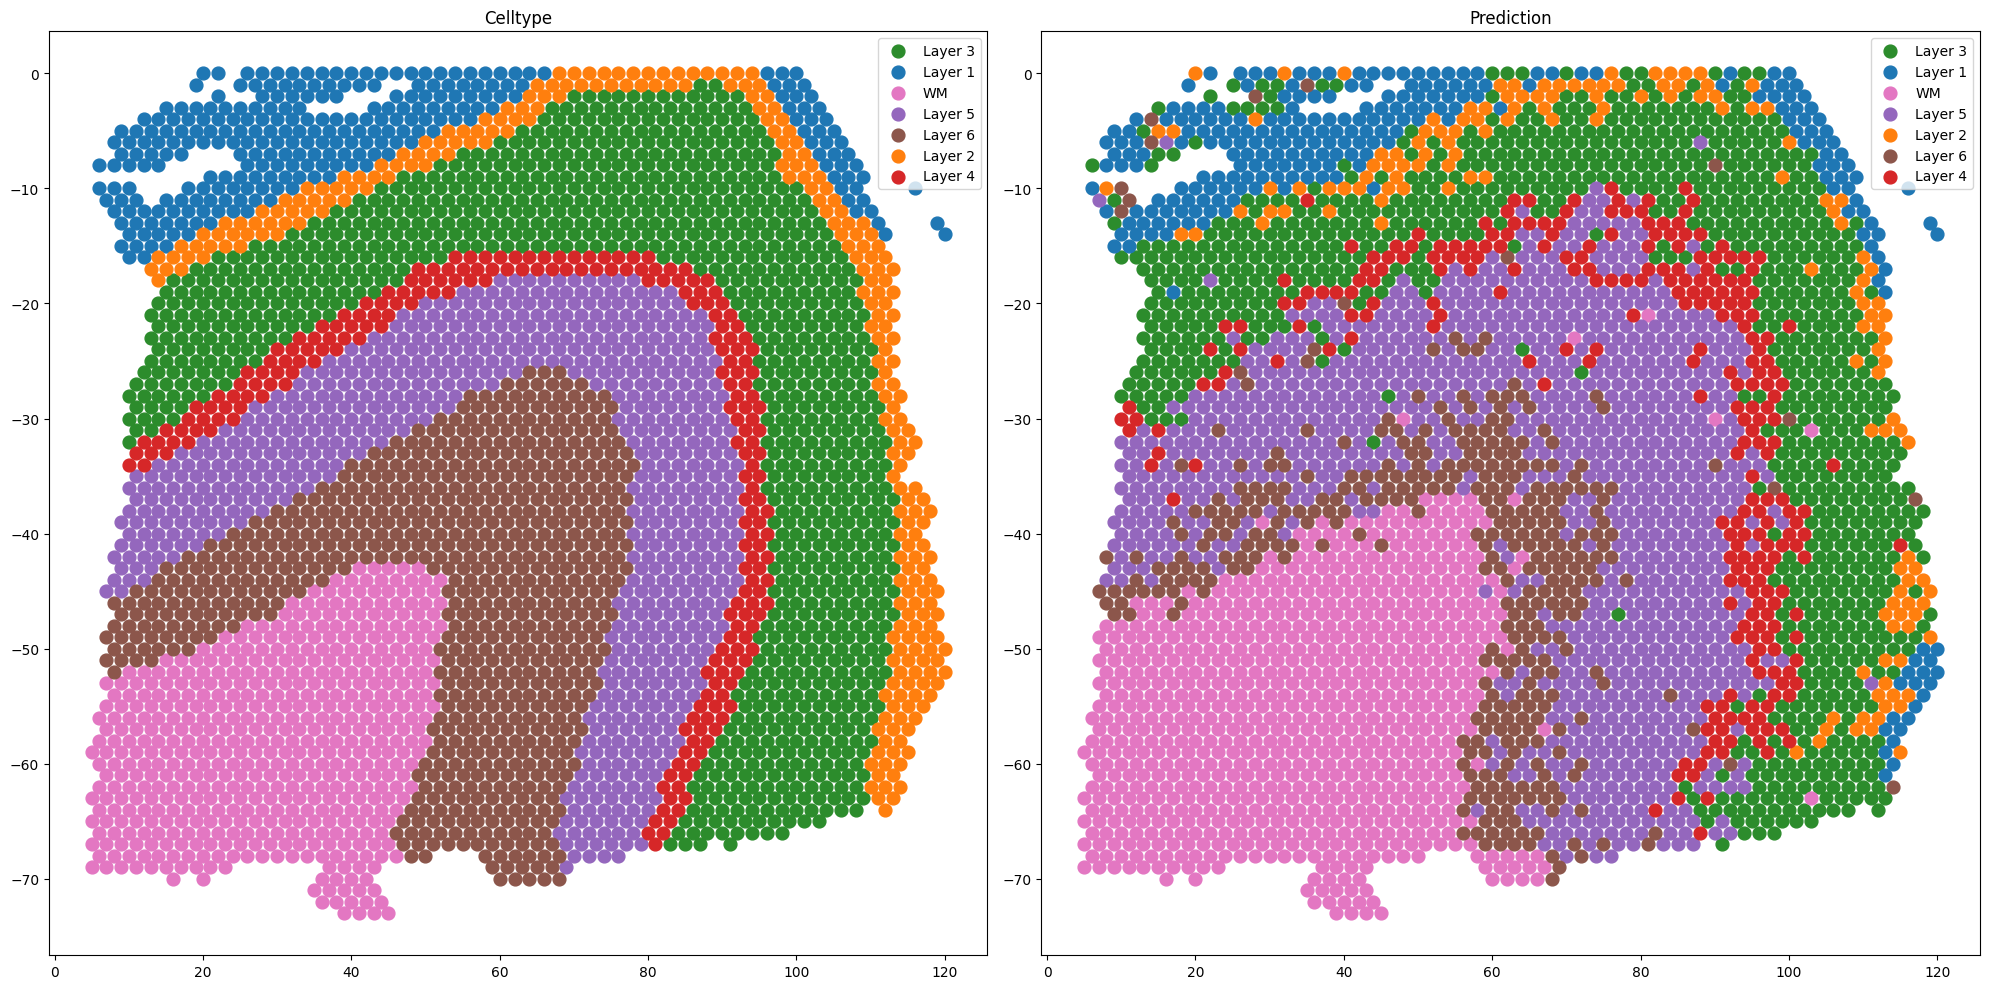

In [8]:
import matplotlib.pyplot as plt

# Preserve the Layer and WM colors defined in train_dlpfc.py.
label_colors = {
    "Layer 1": "#1f77b4", "Layer 3": "#2c8c2c",
    "Layer 5": "#9467bd", "WM": "#e377c2",
    "Layer 2": "#ff7f0e", "Layer 4": "#d62728",
    "Layer 6": "#8c564b",
}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].legend()
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].legend()
axes[1].set_title("Prediction")
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


## Notes

- Query genes must match the model gene names and gene order.
- Replace `QUERY_SAMPLE` with the value stored in `adata.obs["batch"]` for the query graph.